In [2]:
import demes
import demesdraw
import h2py
import moments
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.transforms import ScaledTranslation
import numpy as np


mpl.rc("xtick", labelsize=7)
mpl.rc("ytick", labelsize=7)
mpl.rc("font", size=8)
mpl.rc("axes", labelsize=8)
mpl.rc("axes", titlesize=8)
mpl.rc("legend", fontsize=7)
mpl.rc("axes", titlesize="small")

In [3]:
u = 1.3e-8
rs = np.logspace(-6, -2, 30)
rho = 2e4 * 4 * rs


def get_h2_for_epochs(epochs):
    # epochs is an array of (end_time, start_size), with time in years
    b = demes.Builder(time_units="years", generation_time=29)
    epoch_dicts = [{"end_time": t, "start_size": n} for t, n in epochs[::-1]]
    b.add_deme("pop", epochs=epoch_dicts)
    g = b.resolve()
    stats = moments.Demes.LD(g, ["pop"], u=u, r=rs)
    h2 = stats.H2(0)
    return g, h2, stats

In [4]:
# T, N
one_epoch = np.array(
    [[0, 16700.883020264766],
    [2e6, 16700.883020264766]]
)
two_epoch = np.array(
    [[0, 29559.221908136693],
    [782697.6790850284, 16700.883020264766],
    [2e6, 16700.883020264766]]
)
three_epoch = np.array(
    [[0, 23666.616253261673],
    [57463.82304506533, 29559.221908136693],
    [782697.6790850284, 16700.883020264766],
    [2e6, 16700.883020264766]]
)
four_epoch = np.array(
    [[0, 1e5],
    [30000, 23666.616253261673],
    [57463.82304506533, 29559.221908136693],
    [782697.6790850284, 16700.883020264766],
    [2e6, 16700.883020264766]]
)


equil = np.array(
    [[0, 1.5e4],
    [2e6, 1.5e4]]
)
bot = np.array(
    [[0, 1000],
    [6e4, 1.5e4],
    [2e6, 1.5e4]]
)
recovery = np.array(
    [[0, 1.5e4],
    [4e4, 1000],
    [6e4, 1.5e4],
    [2e6, 1.5e4]]
)
bot_exp = np.array(
    [[0, 1e5],
    [4e4, 1000],
    [6e4, 1.5e4],
    [2e6, 1.5e4]]
)


cousins_eyeball = np.array(
    [[0, 5e4],
    [1e4, 5e4],
    [2e4, 4e4],
    [3e4, 3.5e4],
    [4e4, 2e4],
    [5e4, 1.75e4],
    [6e4, 1.5e4],
    [8e4, 1.75e4],
    [1e5, 2.5e4],
    [2e5, 3.5e4],
    [3e5, 4e4],
    [5e5, 3e4],
    [1e6, 2e4],
    [2e6, 2.5e4],
    [5e6, 2.5e4]]
)
cousins_no_exp = np.array(
    [[0, 1.75e4],
    [8e4, 1.75e4],
    [1e5, 2.5e4],
    [2e5, 3.5e4],
    [3e5, 4e4],
    [5e5, 3e4],
    [1e6, 2e4],
    [2e6, 2.5e4],
    [5e6, 2.5e4]]
)

In [5]:
def get_ghost_model(N, T, f):
    builder = demes.Builder(time_units="years", generation_time=29)
    builder.add_deme("anc", epochs=[{"start_size": 16500, "end_time": 8e5}])
    builder.add_deme("ghost", start_time=T, ancestors=["anc"],
        epochs=[{"start_size": N, "end_time": 8e5}])
    builder.add_deme("denisova", start_time=8e5, ancestors=["anc", "ghost"], proportions=[1 - f, f],
        epochs=[{"start_size": 3e3, "end_time": 60000}])
    builder.add_deme("yoruba", ancestors=["anc"],
        epochs=[{"start_size": 3e4, "end_time": 0}])
    return builder.resolve()


stats_null = moments.Demes.LD(get_ghost_model(1e3, 2e6, 1e-9), ["denisova", "yoruba"], u=u, r=rs)

stats_1e3 = moments.Demes.LD(get_ghost_model(1e3, 2e6, 0.05), ["denisova", "yoruba"], u=u, r=rs)
stats_1e4 = moments.Demes.LD(get_ghost_model(1e4, 2e6, 0.05), ["denisova", "yoruba"], u=u, r=rs)
stats_1e5 = moments.Demes.LD(get_ghost_model(1e5, 2e6, 0.05), ["denisova", "yoruba"], u=u, r=rs)

stats_1e3_2 = moments.Demes.LD(get_ghost_model(1e3, 2e6, 0.2), ["denisova", "yoruba"], u=u, r=rs)
stats_1e4_2 = moments.Demes.LD(get_ghost_model(1e4, 2e6, 0.2), ["denisova", "yoruba"], u=u, r=rs)
stats_1e5_2 = moments.Demes.LD(get_ghost_model(1e5, 2e6, 0.2), ["denisova", "yoruba"], u=u, r=rs)

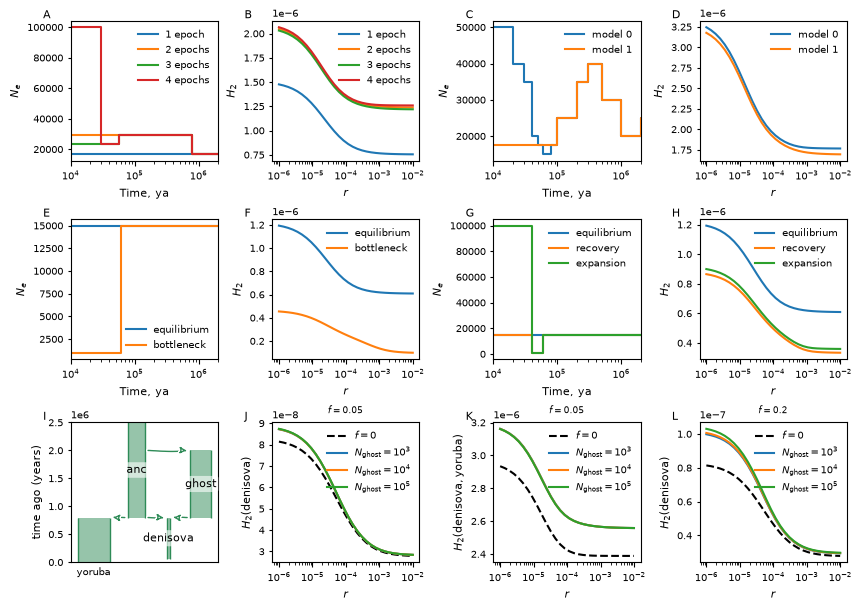

In [9]:
fig, axs = plt.subplot_mosaic("ABCD;EFGH;IJKL", figsize=(8.5, 6), layout="constrained")


ax = "A"
axs[ax].step(one_epoch[::-1, 0], one_epoch[::-1, 1], label="1 epoch")
axs[ax].step(two_epoch[::-1, 0], two_epoch[::-1, 1], label="2 epochs")
axs[ax].step(three_epoch[::-1, 0], three_epoch[::-1, 1], label="3 epochs")
axs[ax].step(four_epoch[::-1, 0], four_epoch[::-1, 1], label="4 epochs")
axs[ax].set_xscale("log")
axs[ax].set_xlim(1e4, 2e6)
axs[ax].set_xlabel("Time, ya")
axs[ax].set_ylabel("$N_e$")
axs[ax].legend(framealpha=0, )

ax = "B"
h0 = get_h2_for_epochs(one_epoch[:-1])[1]
h1 = get_h2_for_epochs(two_epoch[:-1])[1]
h2 = get_h2_for_epochs(three_epoch[:-1])[1]
h3 = get_h2_for_epochs(four_epoch[:-1])[1]
axs[ax].plot(rs, h0, label="1 epoch")
axs[ax].plot(rs, h1, label="2 epochs")
axs[ax].plot(rs, h2, label="3 epochs")
axs[ax].plot(rs, h3, label="4 epochs")
axs[ax].set_xscale("log")
axs[ax].set_xlabel("$r$")
axs[ax].set_ylabel("$H_2$")
axs[ax].legend(framealpha=0, )


ax = "C"
h0 = get_h2_for_epochs(cousins_eyeball[:-1])[1]
h1 = get_h2_for_epochs(cousins_no_exp[:-1])[1]
axs[ax].step(cousins_eyeball[::-1, 0], cousins_eyeball[::-1, 1], label="model 0")
axs[ax].step(cousins_no_exp[::-1, 0], cousins_no_exp[::-1, 1], label="model 1")
axs[ax].set_xscale("log")
axs[ax].set_xlim(1e4, 2e6)
axs[ax].set_xlabel("Time, ya")
axs[ax].set_ylabel("$N_e$")
axs[ax].legend(framealpha=0, )


ax = "D"
axs[ax].plot(rs, h0, label="model 0")
axs[ax].plot(rs, h1, label="model 1")
axs[ax].set_xscale("log")
axs[ax].set_xlabel("$r$")
axs[ax].set_ylabel("$H_2$")
axs[ax].legend(framealpha=0, )


ax = "I"
g_example = get_ghost_model(2e4, 2e6, 0.01)
demesdraw.tubes(g_example, ax=axs[ax], colours="seagreen", inf_ratio=0.2,
                positions={"anc": 0, "yoruba": -4e4, "denisova": 3e4, "ghost": 6e4})
axs[ax].spines["top"].set_visible(True)
axs[ax].spines["right"].set_visible(True)
axs[ax].spines["bottom"].set_visible(True)



ax = "E"
axs[ax].step(equil[::-1, 0], equil[::-1, 1], label="equilibrium")
axs[ax].step(bot[::-1, 0], bot[::-1, 1], label="bottleneck")
axs[ax].set_xscale("log")
axs[ax].set_xlim(1e4, 2e6)
axs[ax].set_xlabel("Time, ya")
axs[ax].set_ylabel("$N_e$")
axs[ax].legend(framealpha=0, )


ax = "F"
h0 = get_h2_for_epochs(equil[:-1])[1]
h1 = get_h2_for_epochs(bot[:-1])[1]
h2 = get_h2_for_epochs(bot_exp[:-1])[1]
axs[ax].plot(rs, h0, label="equilibrium")
axs[ax].plot(rs, h1, label="bottleneck")
axs[ax].set_xscale("log")
axs[ax].set_xlabel("$r$")
axs[ax].set_ylabel("$H_2$")
axs[ax].legend(framealpha=0, )


ax = "G"
axs[ax].step(equil[::-1, 0], equil[::-1, 1], label="equilibrium")
axs[ax].step(recovery[::-1, 0], recovery[::-1, 1], label="recovery")
axs[ax].step(bot_exp[::-1, 0], bot_exp[::-1, 1], label="expansion")
axs[ax].set_xscale("log")
axs[ax].set_xlim(1e4, 2e6)
axs[ax].set_xlabel("Time, ya")
axs[ax].set_ylabel("$N_e$")
axs[ax].legend(framealpha=0, )


ax = "H"
h0 = get_h2_for_epochs(equil[:-1])[1]
h1 = get_h2_for_epochs(recovery[:-1])[1]
h2 = get_h2_for_epochs(bot_exp[:-1])[1]
axs[ax].plot(rs, h0, label="equilibrium")
axs[ax].plot(rs, h1, label="recovery")
axs[ax].plot(rs, h2, label="expansion")
axs[ax].set_xscale("log")
axs[ax].set_xlabel("$r$")
axs[ax].set_ylabel("$H_2$")
axs[ax].legend(framealpha=0, )


ax = "J"
axs[ax].plot(rs, stats_null.H2(0), label="$f=0$", color="black", linestyle="--")
axs[ax].plot(rs, stats_1e3.H2(0), label="$N_\\text{ghost}=10^3$")
axs[ax].plot(rs, stats_1e4.H2(0), label="$N_\\text{ghost}=10^4$")
axs[ax].plot(rs, stats_1e5.H2(0), label="$N_\\text{ghost}=10^5$")
axs[ax].legend(framealpha=0, )
axs[ax].set_xscale("log")
axs[ax].set_xlabel("$r$")
axs[ax].set_ylabel("$H_2(\\text{denisova})$")
axs[ax].set_title("$f=0.05$", )


ax = "K"
axs[ax].plot(rs, stats_null.H2(0, 1, phased=False), label="$f=0$", color="black", linestyle="--")
axs[ax].plot(rs, stats_1e3.H2(0, 1, phased=False), label="$N_\\text{ghost}=10^3$")
axs[ax].plot(rs, stats_1e4.H2(0, 1, phased=False), label="$N_\\text{ghost}=10^4$")
axs[ax].plot(rs, stats_1e5.H2(0, 1, phased=False), label="$N_\\text{ghost}=10^5$")
axs[ax].legend(framealpha=0, )
axs[ax].set_xscale("log")
axs[ax].set_xlabel("$r$")
axs[ax].set_ylabel("$H_2(\\text{denisova}, \\text{yoruba})$")
axs[ax].set_title("$f=0.05$", )


ax = "L"
axs[ax].plot(rs, stats_null.H2(0), label="$f=0$", color="black", linestyle="--")
axs[ax].plot(rs, stats_1e3_2.H2(0), label="$N_\\text{ghost}=10^3$")
axs[ax].plot(rs, stats_1e4_2.H2(0), label="$N_\\text{ghost}=10^4$")
axs[ax].plot(rs, stats_1e5_2.H2(0), label="$N_\\text{ghost}=10^5$")
axs[ax].legend(framealpha=0, )
axs[ax].set_xscale("log")
axs[ax].set_xlabel("$r$")
axs[ax].set_ylabel("$H_2(\\text{denisova})$")
axs[ax].set_title("$f=0.2$", )


for label, ax in axs.items():
    ax.text(0.0, 1.0, label, fontsize="medium", va="bottom", transform=(
        ax.transAxes + ScaledTranslation(-20/72, +0/72, fig.dpi_scale_trans)))

plt.savefig("../../figures/model_assumptions.pdf")